In [592]:
import sys
print(sys.executable)

e:\profile\learning\ml\linear-regression\.venv\Scripts\python.exe


In [593]:
import pandas as pd
print(pd.__version__)

3.0.5


In [594]:
path = "data/california_housing.csv"
df = pd.read_csv(path)


In [595]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
0,-122.23,37.88,41,880,129.0,322,126,8.3252,NEAR BAY,452600
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,NEAR BAY,358500
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,NEAR BAY,352100
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,NEAR BAY,341300
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,NEAR BAY,342200


In [596]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [597]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity', 'median_house_value'],
      dtype='str')

In [598]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   ocean_proximity     20640 non-null  str    
 9   median_house_value  20640 non-null  int64  
dtypes: float64(4), int64(5), str(1)
memory usage: 1.6 MB


In [599]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64

In [600]:
print(df[df["total_bedrooms"].isnull()])

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
290      -122.16     37.77                  47         1256             NaN   
341      -122.17     37.75                  38          992             NaN   
538      -122.28     37.78                  29         5154             NaN   
563      -122.24     37.75                  45          891             NaN   
696      -122.10     37.69                  41          746             NaN   
...          ...       ...                 ...          ...             ...   
20267    -119.19     34.20                  18         3620             NaN   
20268    -119.18     34.19                  19         2393             NaN   
20372    -118.88     34.17                  15         4260             NaN   
20460    -118.75     34.29                  17         5512             NaN   
20484    -118.72     34.28                  17         3051             NaN   

       population  households  median_income ocean_

In [601]:
df = df.dropna()

In [602]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
median_house_value    0
dtype: int64

In [603]:
df.shape

(20433, 10)

In [604]:
df.duplicated().sum()

np.int64(0)

In [605]:
df.boxplot(column="median_income")

<Axes: title={'center': 'Cost Function over Iterations'}, xlabel='Iterations', ylabel='Cost'>

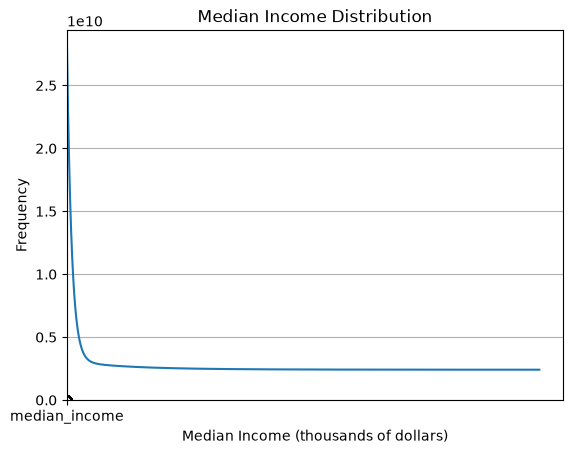

In [606]:
import matplotlib.pyplot as plt
df["median_income"].hist(bins=50)
plt.title("Median Income Distribution")
plt.xlabel("Median Income (thousands of dollars)")
plt.ylabel("Frequency")
plt.show()

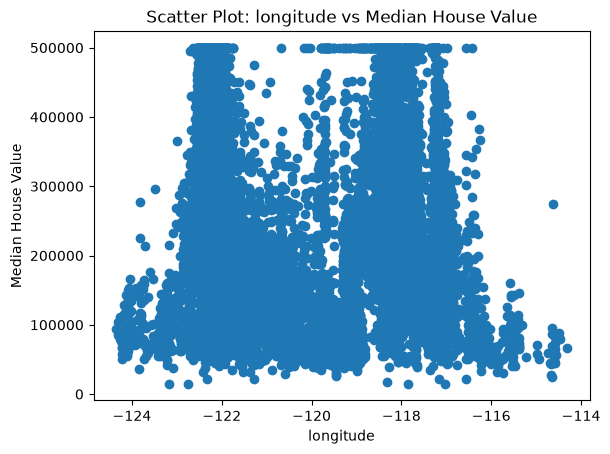

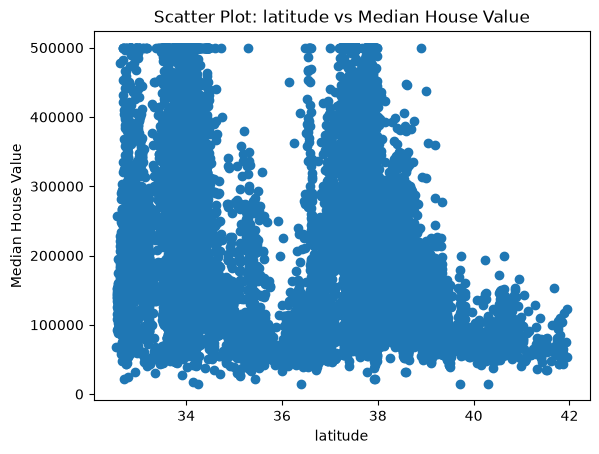

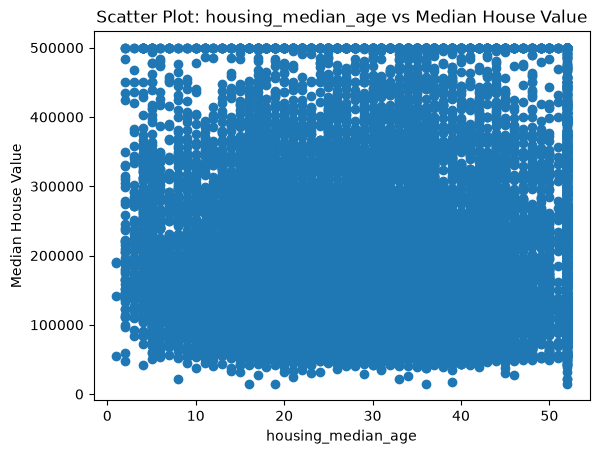

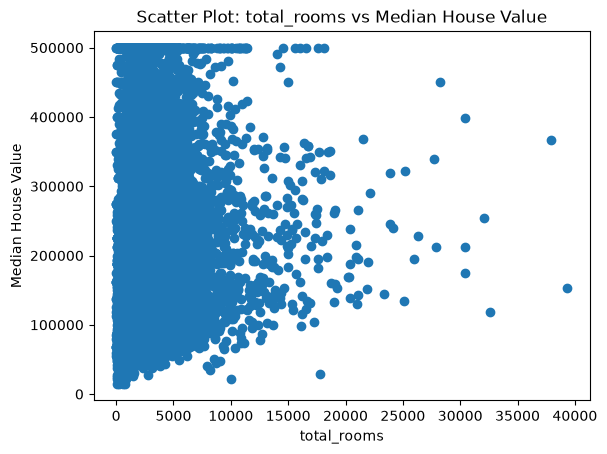

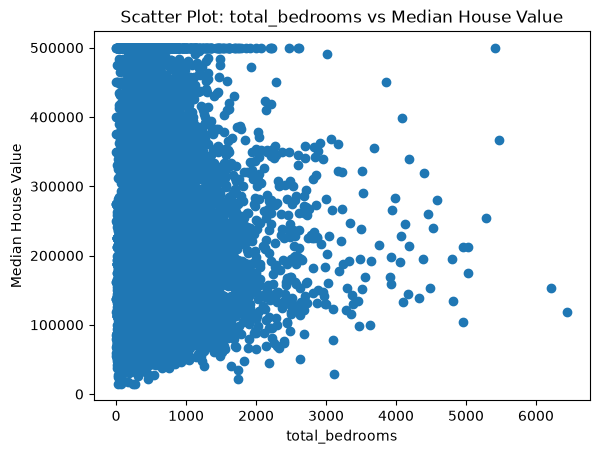

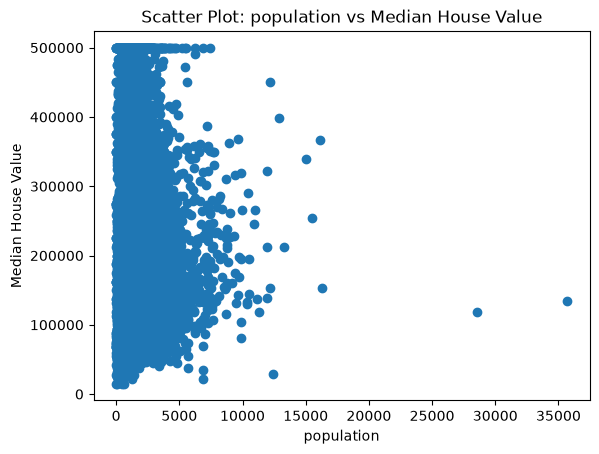

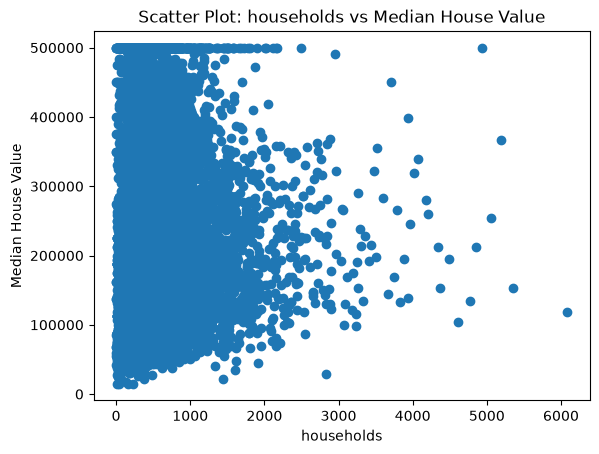

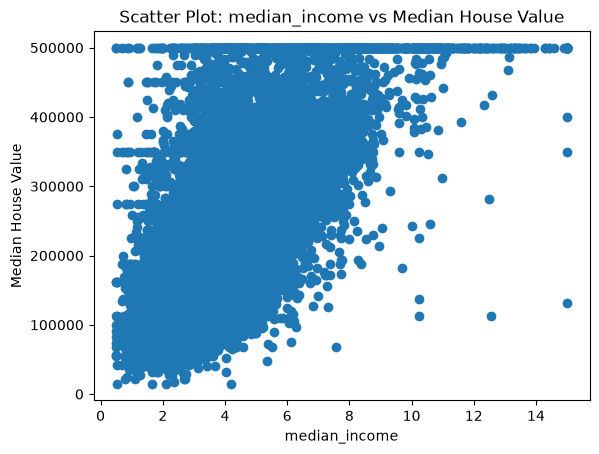

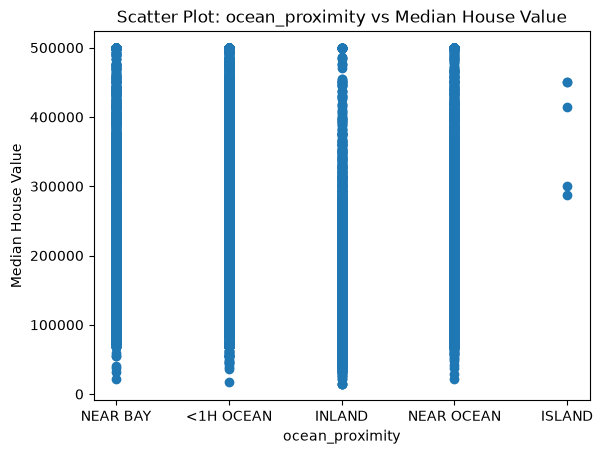

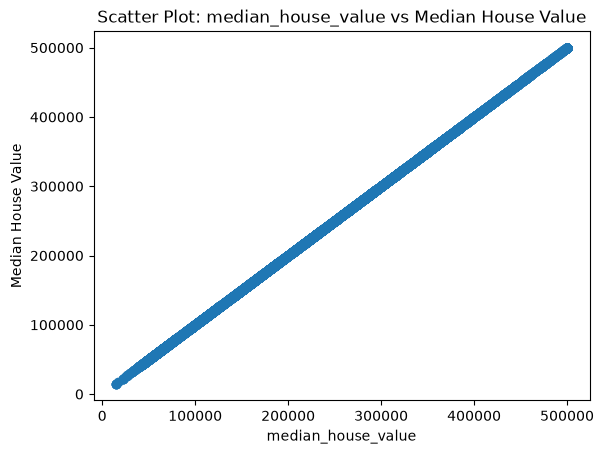

In [607]:
for col in df.columns:
    plt.scatter(df[col], df["median_house_value"])
    plt.xlabel(col)
    plt.ylabel("Median House Value")
    plt.title(f"Scatter Plot: {col} vs Median House Value")
    plt.show()

In [608]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity', 'median_house_value'],
      dtype='str')

In [609]:
df["ocean_proximity"].head()

0    NEAR BAY
1    NEAR BAY
2    NEAR BAY
3    NEAR BAY
4    NEAR BAY
Name: ocean_proximity, dtype: str

In [610]:
df = df.drop(columns=["ocean_proximity"])

In [611]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["median_house_value"])
Y = df["median_house_value"]
X_Train,X_Test,Y_Train,Y_Test = train_test_split(X,Y,test_size=0.2,random_state=42,shuffle=True)

In [612]:
X_Train.shape, X_Test.shape, Y_Train.shape, Y_Test.shape

((16346, 8), (4087, 8), (16346,), (4087,))

In [613]:
X_Train_scaled = pd.DataFrame()
X_Test_scaled = pd.DataFrame()
for col in X_Train.columns:
    X_train_mean_temp = X_Train[col].mean()
    X_train_std_temp = X_Train[col].std()
    X_Train_scaled[col] = (X_Train[col] - X_train_mean_temp) / X_train_std_temp
    X_Test_scaled[col] = (X_Test[col] - X_train_mean_temp) / X_train_std_temp


In [614]:
X_Train_scaled.mean()

longitude            -5.914814e-15
latitude              4.329503e-16
housing_median_age    2.173445e-17
total_rooms          -9.910911e-17
total_bedrooms       -3.999139e-17
population            0.000000e+00
households            3.694857e-17
median_income        -7.302776e-17
dtype: float64

In [615]:
X_Train_scaled.shape[1]

8

In [616]:
import numpy as np
W = np.zeros(X_Train_scaled.shape[1])
bias = 0
costs = []
for i in range(1,2000):
    Y_pred = X_Train_scaled @ W + bias
    error = Y_pred - Y_Train
    cost = (error ** 2).mean()/2
    grad_W = X_Train_scaled.T @ error / len(X_Train_scaled)
    grad_bias = error.mean()

    W -= 0.01 * grad_W
    bias -= 0.01 * grad_bias

    costs.append(cost)
    



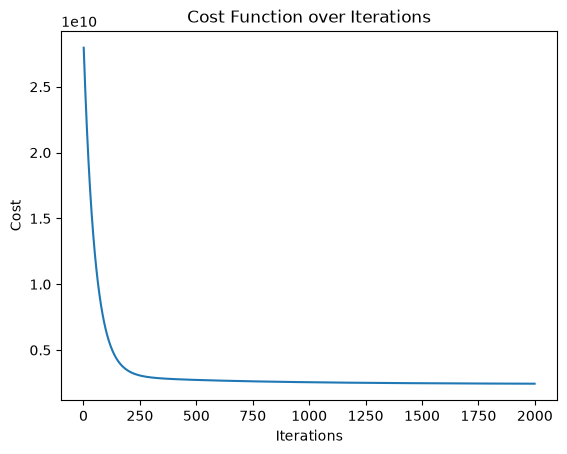

In [617]:
import matplotlib.pyplot as plt

plt.plot(range(1,2000), costs)
plt.title("Cost Function over Iterations")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.show()

In [618]:
Y_pred_test = X_Test_scaled @ W + bias

In [619]:
error_test = Y_pred_test - Y_Test


In [620]:
MSE = (error_test ** 2).mean()
RMSE = np.sqrt(MSE)
R2 = 1 - (error_test.var() / Y_Test.var())

In [621]:
print("DONE")

DONE


In [622]:
print(type(MSE))
print(type(RMSE))
print(type(R2))

<class 'numpy.float64'>
<class 'numpy.float64'>
<class 'numpy.float64'>


In [623]:
print("MSE:", MSE)
print("RMSE:", RMSE)
print("R2:", R2)
print("DONE")

MSE: 5007642485.042277
RMSE: 70764.69801420959
R2: 0.6338872306475736
DONE


In [624]:
RMSE

np.float64(70764.69801420959)

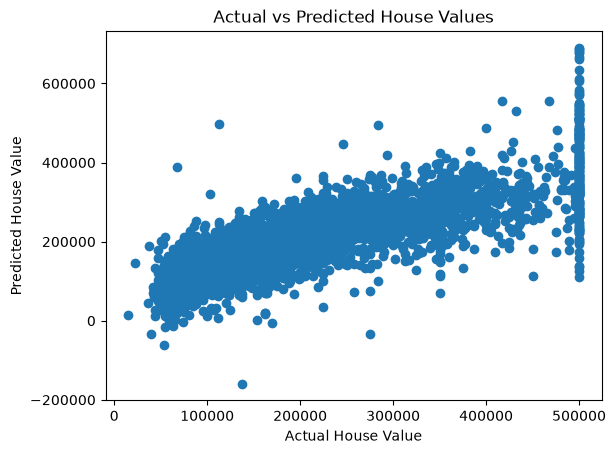

In [625]:
plt.scatter(Y_Test, Y_pred_test)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")
plt.show()

In [626]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_Train_scaled, Y_Train)
Y_pred_test = model.predict(X_Test_scaled)



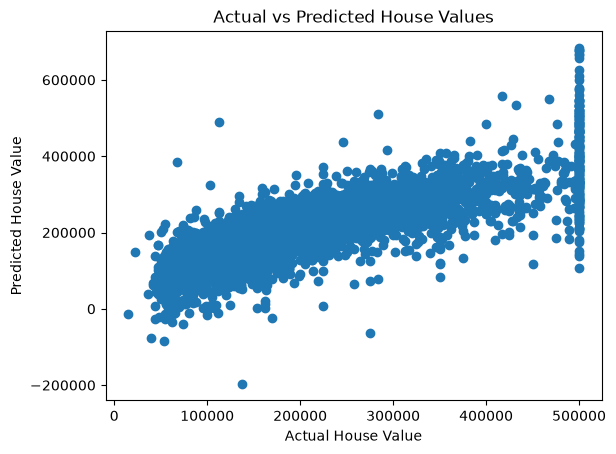

In [627]:
plt.scatter(Y_Test, Y_pred_test)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")
plt.show()

In [628]:
error_test_sklearn = Y_pred_test - Y_Test

MSE_sklearn = (error_test_sklearn ** 2).mean()
RMSE_sklearn = np.sqrt(MSE_sklearn)
R2_sklearn = 1 - (error_test_sklearn.var() / Y_Test.var())

print("MSE:", MSE_sklearn)
print("RMSE:", RMSE_sklearn)
print("R2:", R2_sklearn)

MSE: 4921881237.628146
RMSE: 70156.12045736385
R2: 0.6401989067858547
